In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import importlib

import sys
import json
import analysis_functions
importlib.reload(analysis_functions)
from analysis_functions import *
import copy

sys.path.insert(0, "..")
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

from numeric_method.numeric_method import solve_navier_stokes
from modeling.data import geometry_to_mtx

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
    "axes.labelsize": 12,
    "font.size": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

## Pipe

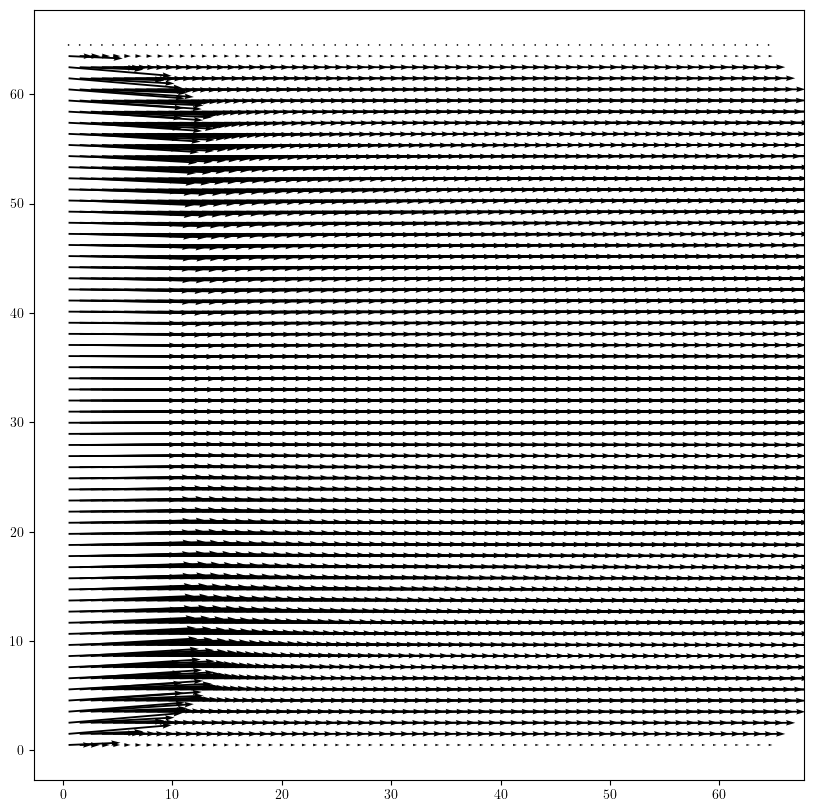

In [2]:
ux = np.load("../../data/CFDBench/tube/bc/case0049/u.npy") 
uy = np.load("../../data/CFDBench/tube/bc/case0049/v.npy")
with open("../../data/CFDBench/tube/bc/case0049/case.json", "r") as f:
    case_ = json.load(f)

with open("../../data/cases/pipe.json", "r") as f:
    case_nm = json.load(f)

fig, ax = plt.subplots(1, 1, figsize=(10, 10))
plot_velocity(ax, ux[-1], uy[-1], scale=0.5)
plt.show()

In [3]:
case_

{'height': 0.1, 'width': 1, 'vel_in': 5.0, 'density': 100, 'viscosity': 0.1}

In [3]:
height_phys = case_["height"]
width_phys = case_["width"]
inflow = case_["vel_in"]
density = case_["density"]
viscosity = case_["viscosity"]

# viscosity = viscosity / density
# viscosity = viscosity * density
# viscosity = 0.1
# density = 1

beta = 1

height_px = np.shape(ux)[1]
width_px = np.shape(ux)[2]

dy = height_phys / height_px
dx = width_phys / width_px

dx = dy
# dx = 0.0012
# dy = 0.0012

case_nm["width"] = width_px
case_nm["height"] = height_px
case_nm["dx"] = dx
case_nm["dy"] = dy
case_nm["density"] = density
case_nm["viscosity"] = viscosity
case_nm["beta"] = beta

C = 10
case_nm["time_step"] = 0.1 #np.max([dy, dx]) * C / inflow

L = 0

for gi in range(len(case_nm["geometry"])):
    if case_nm["geometry"][gi]["type"] == "inflow":
        case_nm["geometry"][gi]["vel"]["x"] = inflow
        L = case_nm["geometry"][gi]["size"]["height"] * dy
        break

display(case_nm)

{'width': 64,
 'height': 64,
 'dx': 0.0015625,
 'dy': 0.0015625,
 'iterations': 500,
 'time_step': 0.1,
 'density': 100,
 'viscosity': 0.1,
 'beta': 1,
 'geometry': [{'type': 'outflow',
   'pos': {'x': -1, 'y': 0},
   'size': {'width': 1, 'height': -1},
   'dir': {'x': -1, 'y': 0}},
  {'type': 'inflow',
   'pos': {'x': 0, 'y': 0},
   'size': {'width': 1, 'height': -1},
   'vel': {'x': 5.0, 'y': 0}},
  {'type': 'wall',
   'pos': {'x': 0, 'y': 0},
   'size': {'width': -1, 'height': 1},
   'dir': {'x': 0, 'y': 1}},
  {'type': 'wall',
   'pos': {'x': 0, 'y': -1},
   'size': {'width': -1, 'height': 1},
   'dir': {'x': 0, 'y': -1}}]}

In [42]:
Re = (density * inflow * L) / case_["viscosity"]

print(f"Reynolds number = {Re}")

Reynolds number = -7.8125


	 -> Creating discrete Laplacian matrix...
	 -> Creating discrete Laplacian matrix...
	 -> Iterating...


     : 100%|██████████| 1500/1500 [03:57<00:00,  6.32it/s]


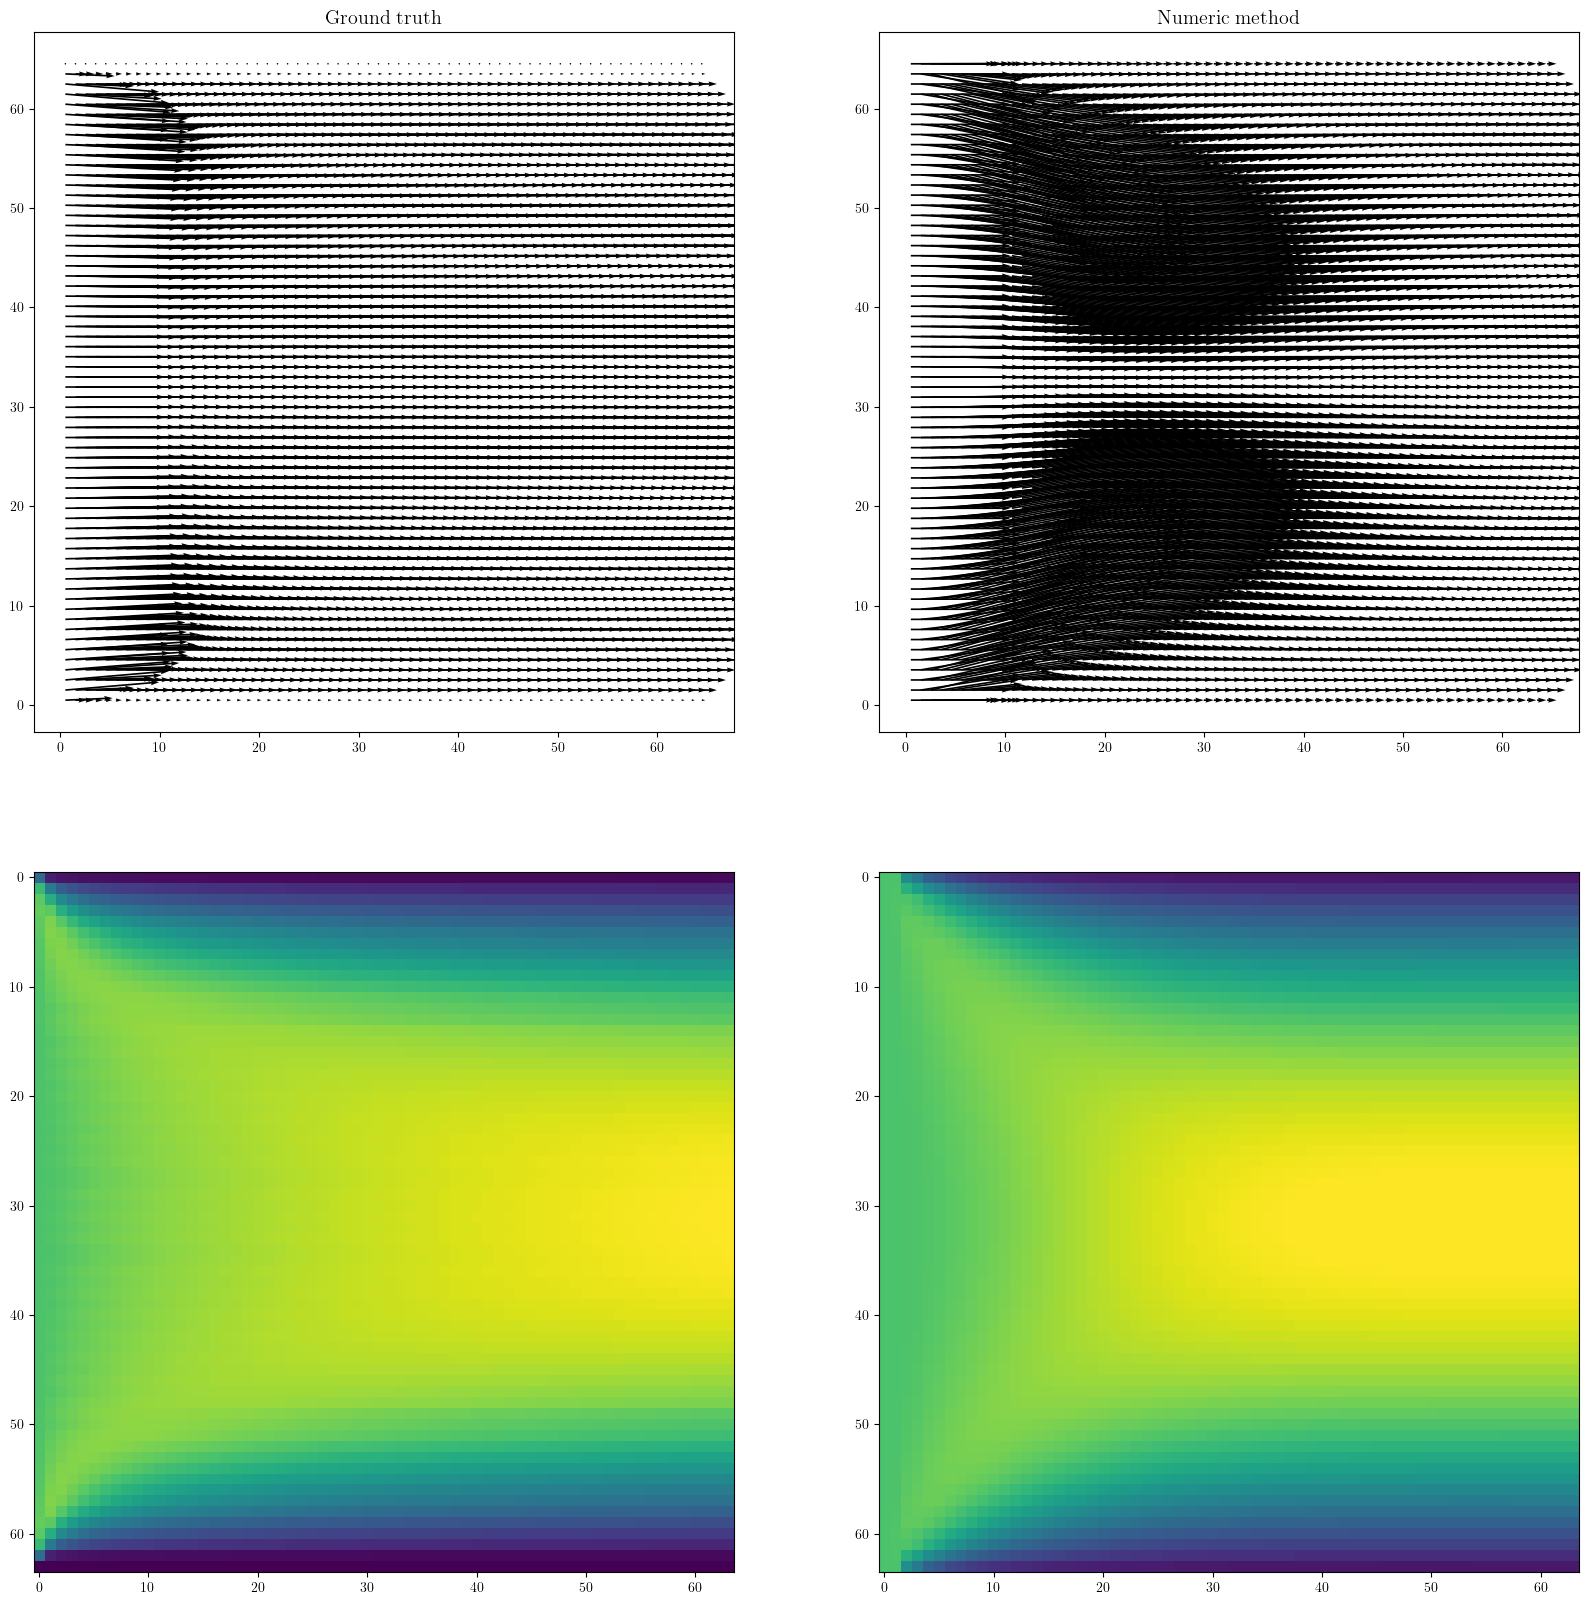

In [4]:
u, p, u_star, div_u_star, phi = solve_navier_stokes(
    case_nm["width"],
    # 370,
    case_nm["height"],
    dx,
    dy,
    int(case_nm["iterations"]) * 3,
    case_nm["time_step"],
    case_nm["density"],
    case_nm["viscosity"],
    case_nm["beta"],
    case_nm["geometry"],
    dynamic_time_step=True,
    implicit_laplacian=True,
    return_div_u_star=True,
    method_type="numeric"
)

# u = [u[i][1:-1, 1:-1, :] for i in range(len(u))]
# p = [p[i][1:-1, 1:-1] for i in range(len(p))]

# u = [u[i][:, 300:364, :] for i in range(len(u))]
# p = [p[i][:, 300:364] for i in range(len(p))]

# u = [u[i][:, :64, :] for i in range(len(u))]
# p = [p[i][:, :64] for i in range(len(p))]

u_nm = np.transpose(u[-1], (2, 0, 1))
u_baseline = np.stack([ux[-1], uy[-1]], axis=0)

_, _, _, _, _, _, boundary = geometry_to_mtx(case_nm["geometry"], width_px, height_px)

fig, ax = plt.subplots(2, 2, figsize=(20, 20))
ax = ax.flatten()
plot_velocity(ax[0], ux[-1], uy[-1], scale=0.5)
plot_velocity(ax[1], u[-1][:, :, 0], u[-1][:, :, 1], scale=0.5)
ax[0].set_title("Ground truth")
ax[1].set_title("Numeric method")

gt_norm = np.linalg.norm(np.stack((ux[-1], uy[-1])), axis=0)
nm_norm = np.linalg.norm(np.stack(u[-1]), axis=-1)
vmin = min(gt_norm.min(), nm_norm.min())
vmax = min(gt_norm.max(), nm_norm.max())

ax[2].imshow(gt_norm, vmin=vmin, vmax=vmax)
ax[3].imshow(nm_norm, vmin=vmin, vmax=vmax)

plt.show()

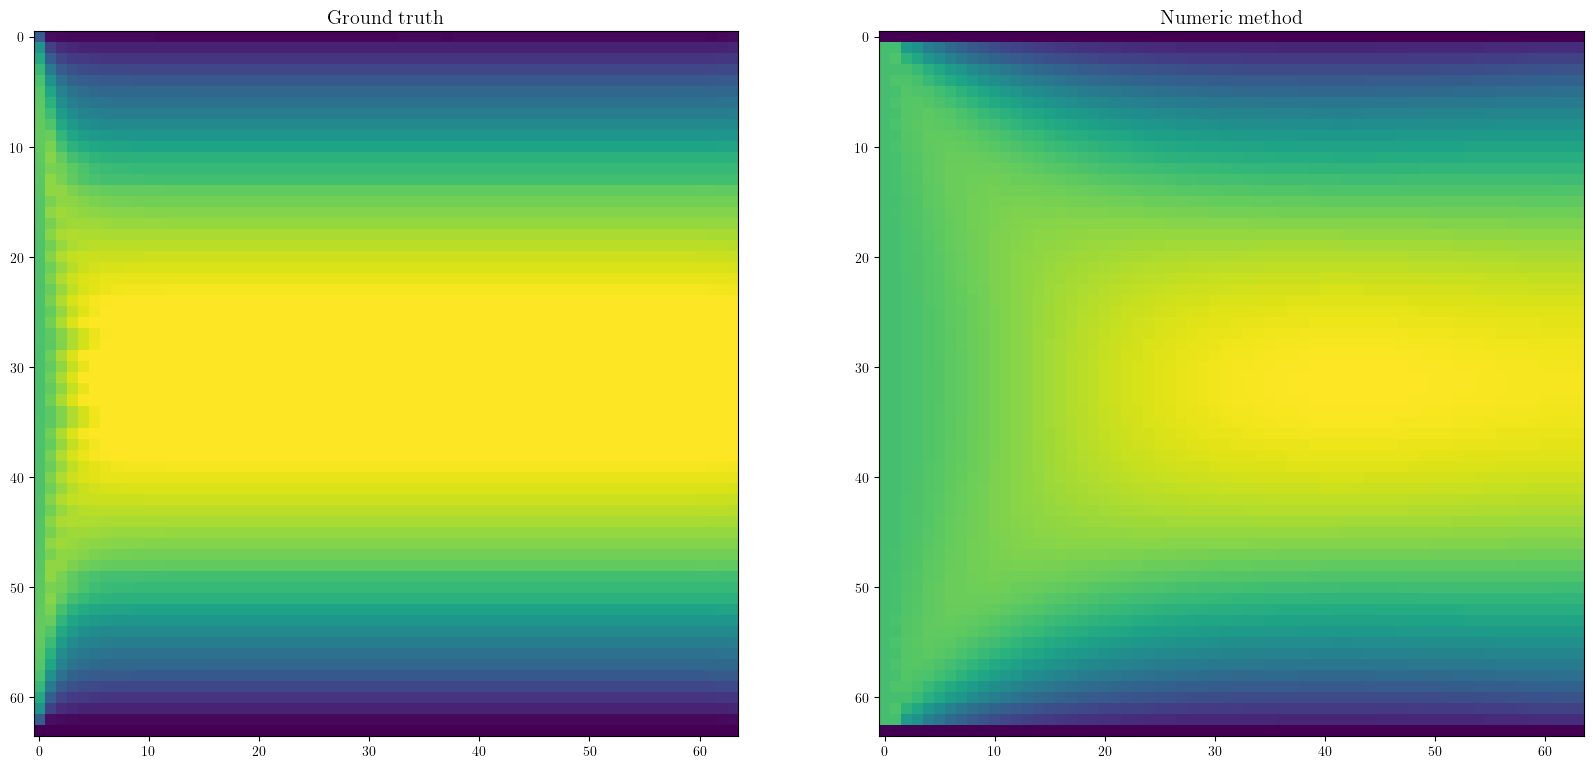

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(20, 10))
# plot_velocity(ax[0], ux[-1], uy[-1], scale=0.5)
gt_norm = np.linalg.norm(np.stack((ux[-1], uy[-1])), axis=0)
nm_norm = np.linalg.norm(np.stack(u[-1]), axis=-1)
vmin = min(gt_norm.min(), nm_norm.min())
vmax = min(gt_norm.max(), nm_norm.max())
ax[0].imshow(gt_norm, vmin=vmin, vmax=vmax)
ax[1].imshow(nm_norm, vmin=vmin, vmax=vmax)
# plot_velocity(ax[1], u[-1][:, :, 0], u[-1][:, :, 1], scale=0.5)
ax[0].set_title("Ground truth")
ax[1].set_title("Numeric method")
plt.show()

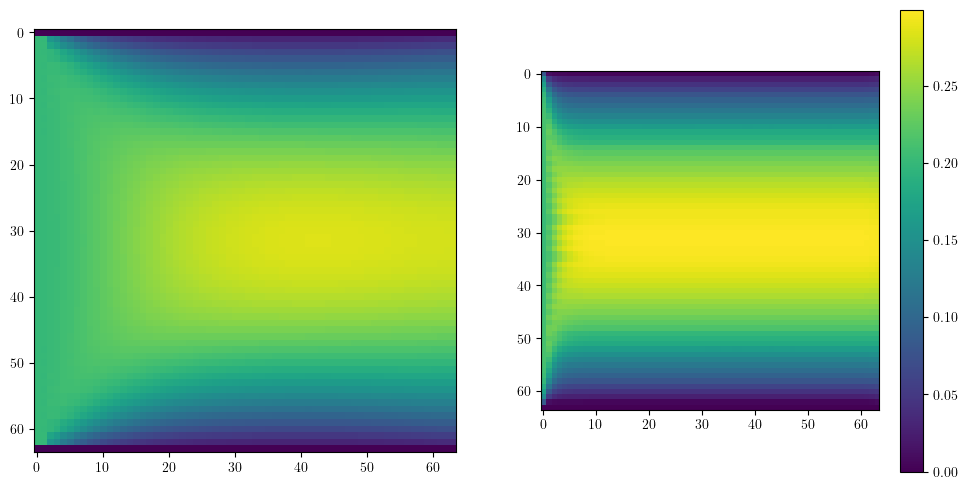

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

vmin = min(u[-1][:, :, 0].min(), ux[-1].min())
vmax = max(u[-1][:, :, 0].max(), ux[-1].max())

ax[0].imshow(u[-1][:, :, 0], vmin=vmin, vmax=vmax)
im = ax[1].imshow(ux[-1], vmin=vmin, vmax=vmax)
plt.colorbar(im)
plt.show()

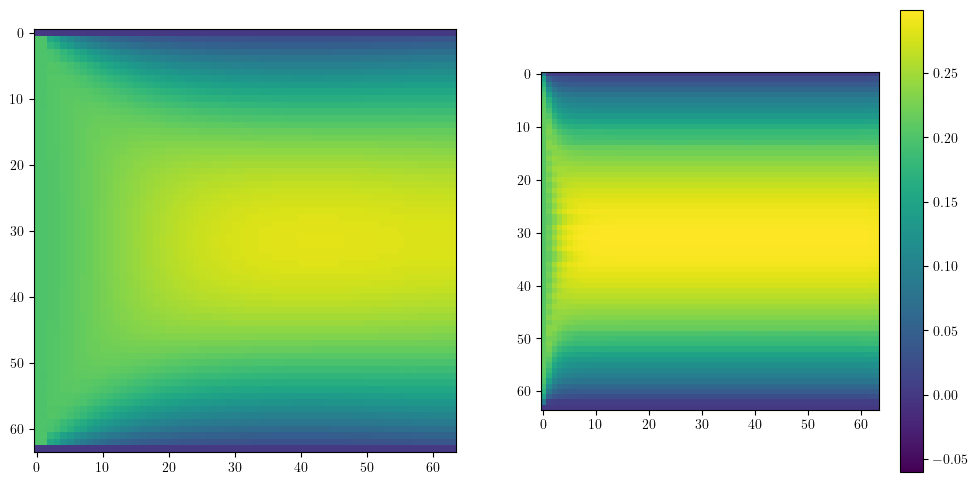

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

vmin = min(u[-1][:, :, 1].min(), ux[-1].min())
vmax = max(u[-1][:, :, 1].max(), ux[-1].max())

ax[0].imshow(u[-1][:, :, 0], vmin=vmin, vmax=vmax)
im = ax[1].imshow(ux[-1], vmin=vmin, vmax=vmax)
plt.colorbar(im)
plt.show()

In [21]:
print(f"{np.mean(u_nm)} +- {np.std(u_nm)}")
print(f"{np.mean(u_baseline)} +- {np.std(u_baseline)}")

0.09685981839275898 +- 0.11077483330722945
0.09762167439651372 +- 0.11701291987747515


0.023642843461672478


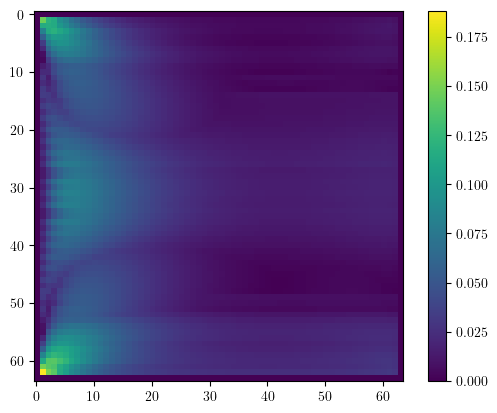

In [22]:
err_vec_inf = pointwise_inf(u_baseline, u_nm) * (1 - boundary)
print(np.mean(err_vec_inf))

plt.imshow(err_vec_inf)
plt.colorbar()
plt.show()

0.018003455390556086


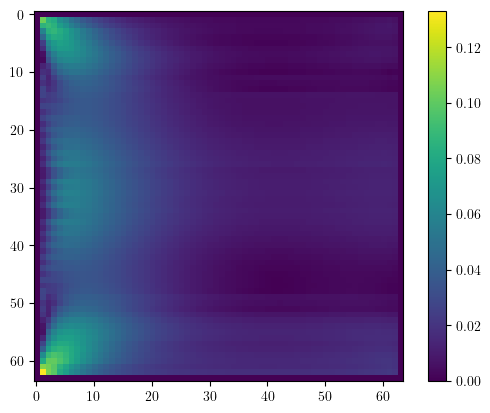

In [23]:
err_vec_2 =  pointwise_rmse(u_baseline, u_nm) * (1 - boundary)
print(np.mean(err_vec_2))

plt.imshow(err_vec_2)
plt.colorbar()
plt.show()

0.015570974279340281


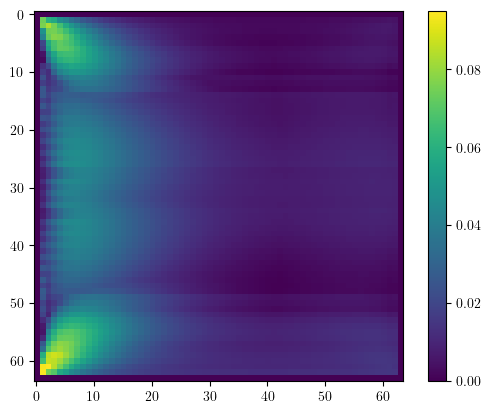

In [24]:
err_vec_1 = pointwise_l1(u_baseline, u_nm) * (1 - boundary)
print(np.mean(err_vec_1))

plt.imshow(err_vec_1)
plt.colorbar()
plt.show()

## Cylinder

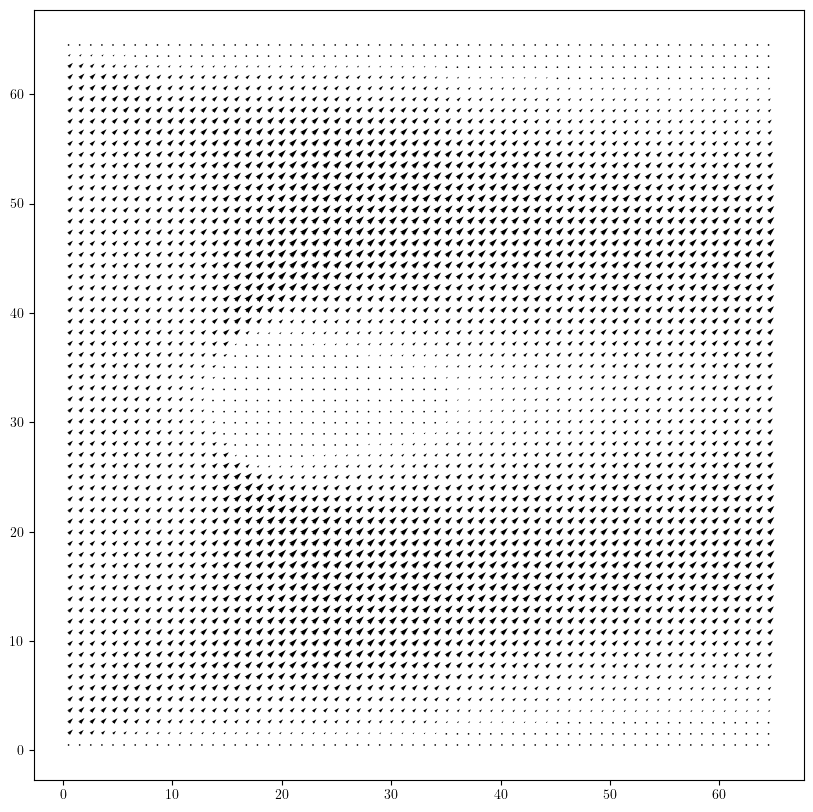

In [2]:
ux = np.load("../../data/CFDBench/cylinder/bc/case0001/u.npy") 
uy = np.load("../../data/CFDBench/cylinder/bc/case0001/v.npy")
with open("../../data/CFDBench/cylinder/bc/case0001/case.json", "r") as f:
    case_ = json.load(f)

with open("../../data/cases/cylinder.json", "r") as f:
    case_nm = json.load(f)

fig, ax = plt.subplots(1, 1, figsize=(10, 10))
plot_velocity(ax, ux[-1], uy[-1], scale=0.5)
plt.show()

In [3]:
radius_phys = case_["radius"]
x_phys = abs(case_["x_min"]) + radius_phys
y_phys = abs(case_["y_min"]) + radius_phys

height_phys = abs(case_["y_min"]) + 2 * radius_phys + abs(case_["y_max"])
width_phys = abs(case_["x_min"]) + 2 * radius_phys + abs(case_["x_max"])
inflow = case_["vel_in"]
density = case_["density"]
viscosity = case_["viscosity"]

viscosity = viscosity / density

beta = 0

height_px = np.shape(ux)[1]
width_px = np.shape(ux)[2]

dy = height_phys / height_px
dx = width_phys / width_px

radius = 2 * int(radius_phys / min(dx, dy))
x = int(x_phys / dx)
y = int(y_phys / dy)

case_nm["width"] = width_px
case_nm["height"] = height_px
case_nm["dx"] = dx
case_nm["dy"] = dy
case_nm["density"] = density
case_nm["viscosity"] = viscosity
case_nm["beta"] = beta

C = 10
case_nm["time_step"] = 0.1 #np.max([dy, dx]) * C / inflow

for gi in range(len(case_nm["geometry"])):
    if case_nm["geometry"][gi]["type"] == "inflow":
        case_nm["geometry"][gi]["vel"]["x"] = inflow

    if case_nm["geometry"][gi]["type"] == "cylinder":
        case_nm["geometry"][gi]["pos"]["x"] = x
        case_nm["geometry"][gi]["pos"]["y"] = y
        case_nm["geometry"][gi]["size"] = radius

display(case_nm)


{'width': 64,
 'height': 64,
 'dx': 0.00375,
 'dy': 0.0021875,
 'iterations': 100,
 'time_step': 0.1,
 'density': 10,
 'viscosity': 0.0001,
 'beta': 0,
 'geometry': [{'type': 'wall',
   'pos': {'x': 0, 'y': 0},
   'size': {'width': -1, 'height': 1},
   'dir': {'x': 0, 'y': 1}},
  {'type': 'wall',
   'pos': {'x': 0, 'y': -1},
   'size': {'width': -1, 'height': 1},
   'dir': {'x': 0, 'y': -1}},
  {'type': 'outflow',
   'pos': {'x': -1, 'y': 0},
   'size': {'width': 1, 'height': 64},
   'dir': {'x': -1, 'y': 0}},
  {'type': 'cylinder', 'pos': {'x': 18, 'y': 31}, 'size': 8},
  {'type': 'inflow',
   'pos': {'x': 0, 'y': 0},
   'size': {'width': 1, 'height': 64},
   'vel': {'x': 0.2, 'y': 0}}]}

	 -> Creating discrete Laplacian matrix...
	 -> Creating discrete Laplacian matrix...
	 -> Iterating...


     : 100%|██████████| 300/300 [00:11<00:00, 26.16it/s]


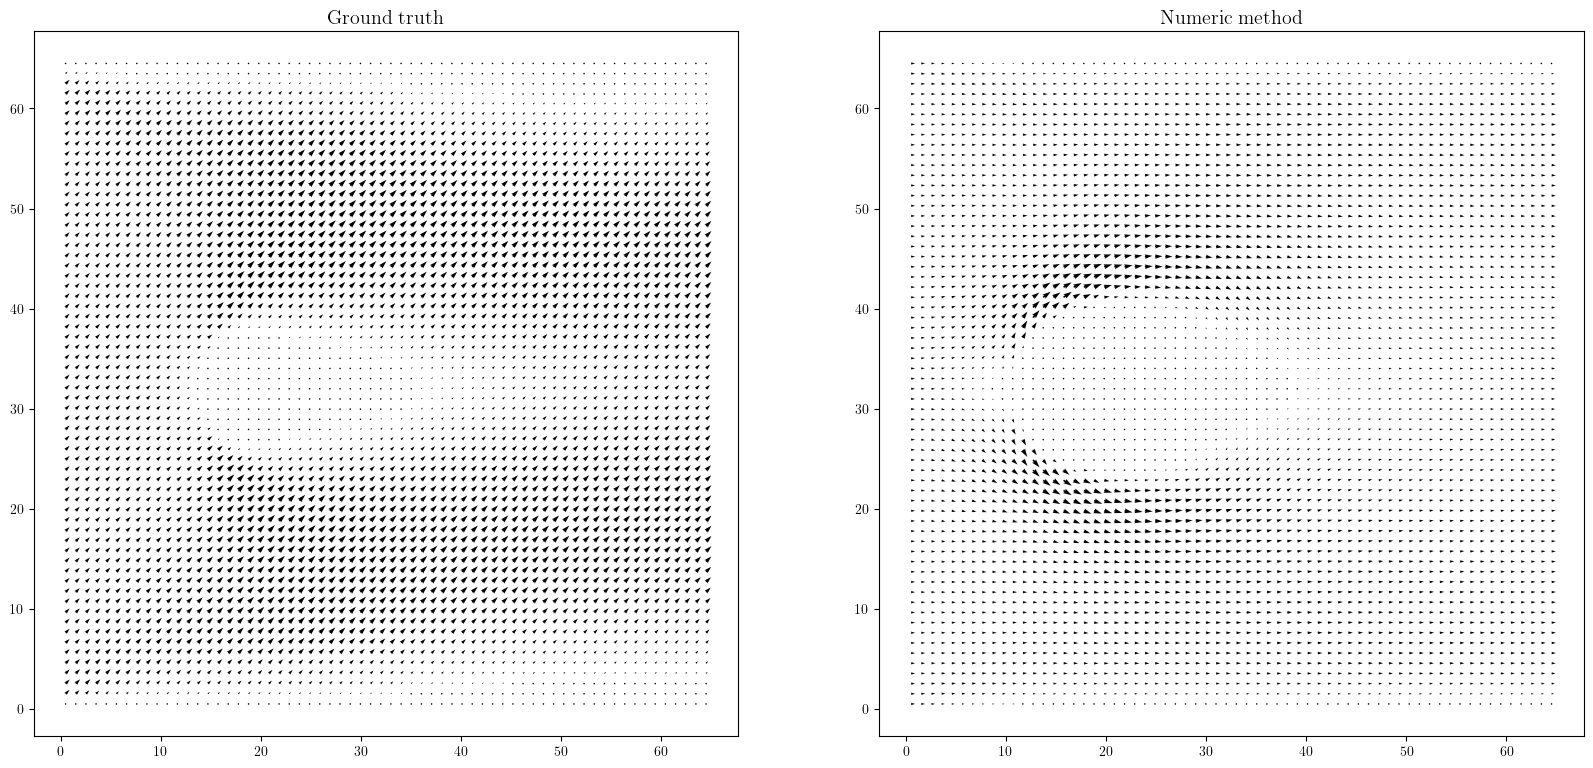

In [4]:
u, p, u_star, div_u_star, phi = solve_navier_stokes(
    case_nm["width"],
    # 370,
    case_nm["height"],
    dx,
    dy,
    case_nm["iterations"] * 3,
    case_nm["time_step"],
    case_nm["density"],
    case_nm["viscosity"],
    case_nm["beta"],
    case_nm["geometry"],
    dynamic_time_step=True,
    implicit_laplacian=True,
    return_div_u_star=True,
    method_type="numeric"
)

u_nm = np.transpose(u[-1], (2, 0, 1))
u_baseline = np.stack([ux[-1], uy[-1]], axis=0)

_, _, _, _, _, _, boundary = geometry_to_mtx(case_nm["geometry"], width_px, height_px)

fig, ax = plt.subplots(1, 2, figsize=(20, 10))
plot_velocity(ax[0], ux[-1], uy[-1], scale=0.5)
plot_velocity(ax[1], u[-1][:, :, 0], u[-1][:, :, 1], scale=0.5)
ax[0].set_title("Ground truth")
ax[1].set_title("Numeric method")
plt.show()

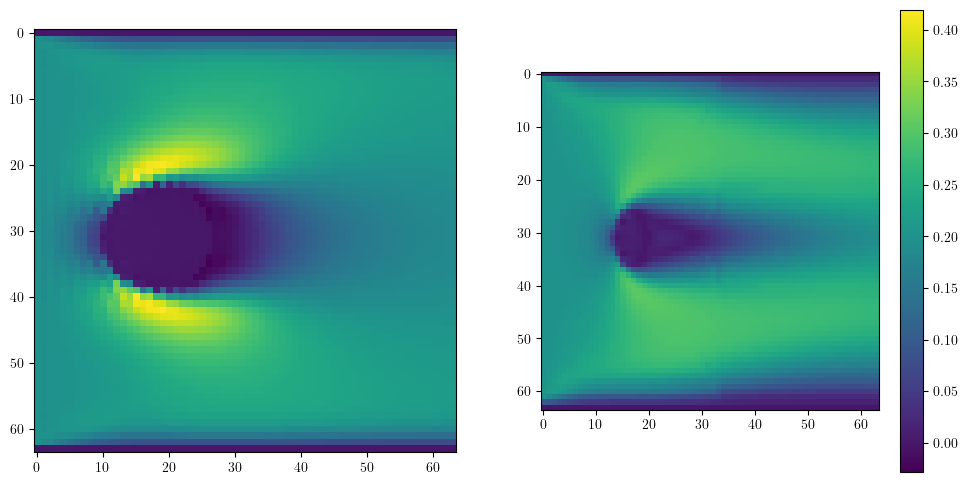

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

vmin = min(u[-1][:, :, 0].min(), ux[-1].min())
vmax = max(u[-1][:, :, 0].max(), ux[-1].max())

ax[0].imshow(u[-1][:, :, 0], vmin=vmin, vmax=vmax)
im = ax[1].imshow(ux[-1], vmin=vmin, vmax=vmax)
plt.colorbar(im)
plt.show()

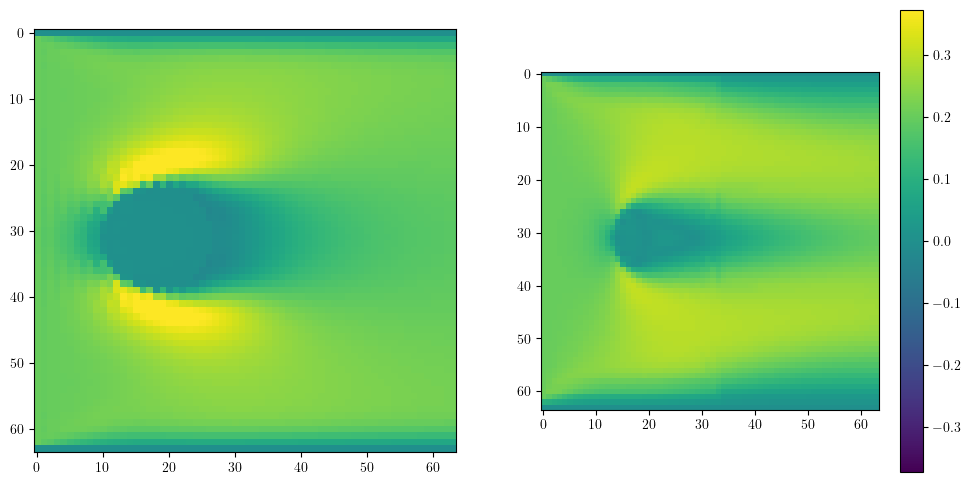

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

vmin = min(u[-1][:, :, 1].min(), ux[-1].min())
vmax = max(u[-1][:, :, 1].max(), ux[-1].max())

ax[0].imshow(u[-1][:, :, 0], vmin=vmin, vmax=vmax)
im = ax[1].imshow(ux[-1], vmin=vmin, vmax=vmax)
plt.colorbar(im)
plt.show()

In [15]:
print(f"{np.mean(u_nm)} +- {np.std(u_nm)}")
print(f"{np.mean(u_baseline)} +- {np.std(u_baseline)}")

0.09442566800464192 +- 0.11854490789503541
0.19597930988438064 +- 0.08412526649830858


0.19030714754901595


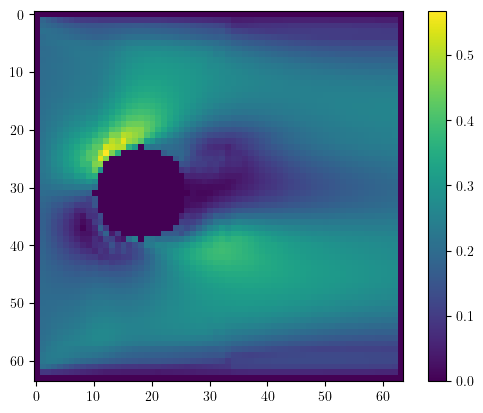

In [16]:
err_vec_inf = pointwise_inf(u_baseline, u_nm) * (1 - boundary)
print(np.mean(err_vec_inf))

plt.imshow(err_vec_inf)
plt.colorbar()
plt.show()

0.13835284161201902


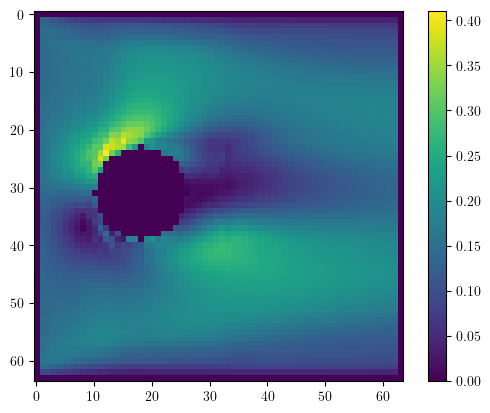

In [17]:
err_vec_2 =  pointwise_rmse(u_baseline, u_nm) * (1 - boundary)
print(np.mean(err_vec_2))

plt.imshow(err_vec_2)
plt.colorbar()
plt.show()

0.1117544860709764


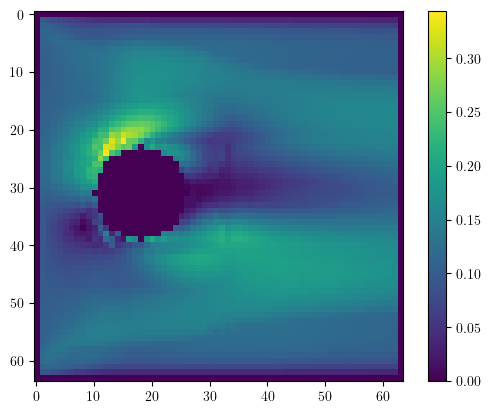

In [18]:
err_vec_1 = pointwise_l1(u_baseline, u_nm) * (1 - boundary)
print(np.mean(err_vec_1))

plt.imshow(err_vec_1)
plt.colorbar()
plt.show()

## Dam

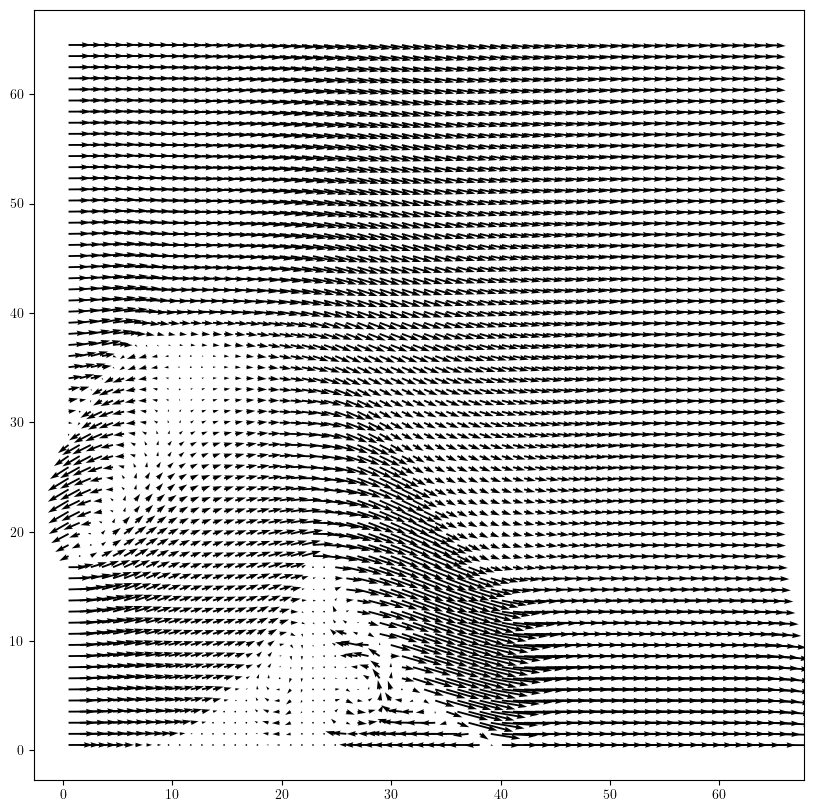

In [ ]:
ux = np.load("../../data/CFDBench/dam/bc/case0030/u.npy") 
uy = np.load("../../data/CFDBench/dam/bc/case0030/v.npy")
with open("../../data/CFDBench/dam/bc/case0030/case.json", "r") as f:
    case_ = json.load(f)

with open("../../data/cases/dam.json", "r") as f:
    case_nm = json.load(f)

fig, ax = plt.subplots(1, 1, figsize=(10, 10))
plot_velocity(ax, ux[-1], uy[-1], scale=0.5)
plt.show()